# Part 2: Breaking LWE with Lattice Reduction

In the first part about LWE, we studied the decryption reliability of LWE and the impact of $\sigma$, $m$, $n$ and $q$. In this second part, we will focus on the attacker's perspective by trying to break LWE with the LLL algorithm.
Our goal is to explain that LWE is a lattice problem that is related to the closest vector problem.
Indeed, all the vectors of the form $Az \pmod q, z \in \mathbb{Z}^{n}$ form a lattice and $As$ is one of its points.
Since $b = As + e \pmod q$, the smaller $e$ is the closer to $As$ b is. On the other hand, if $e$ is too large, $b$ may end up closer to another lattice point than to $As$.
This highlights that $\sigma$ has to be large enough to guarantee security but also small enough to guarantee decryption reliability.

Plan :

1) Lattices: a short reminder of what a lattice is and why LWE can be seen as a lattice problem.
2) The LLL algorithm: implementation and test
3) The attack: transform LWE into a lattice problem and solve it
4) Experiments: when does the attack succeed?
5) Conclusion: compromise between security and decryption, towards Kyber.

## 1. Lattices: a short reminder of what a lattice is and why LWE can be seen as a lattice problem.

**Definition.** A lattice $\mathcal{L}$ in $\mathbb{R}^n$ is the set of all integer linear combinations of $m$ linearly independent vectors $b_1, \dots, b_m$ (with $m \le n$):

$$\mathcal{L}(B) = \{ x_1 b_1 + \dots + x_m b_m \mid x_i \in \mathbb{Z} \}.$$

The vectors $b_1, \dots, b_m$ form an ordered basis $B = [b_1, \dots, b_m]$ of $\mathcal{L}$. We write them as the **columns** of the matrix $B$, so that $\mathcal{L}(B) = \{ Bx : x \in \mathbb{Z}^m \}$.
The dimension of $\mathcal{L}$ is $n$ and its rank is $m$. In this notebook, we assume $b_1, \dots, b_m \in \mathbb{Z}^n$.

### Example: two bases of the same lattice

Let $n = 2$ and consider the two bases
$$B = [(2,0), (0,1)] \qquad \text{and} \qquad B' = [(-2,-2), (4,3)].$$

We claim that $\mathcal{L}(B) = \mathcal{L}(B')$.

**Proof.** Since a lattice is closed under integer linear combinations, it is enough to check that the basis vectors of each basis belong to the other lattice.

- $\mathcal{L}(B) \subseteq \mathcal{L}(B')$, since
  $(2,0) = 3 \cdot (-2,-2) + 2 \cdot (4,3)$ and $(0,1) = -2 \cdot (-2,-2) - 1 \cdot (4,3)$.
- $\mathcal{L}(B') \subseteq \mathcal{L}(B)$, since
  $(-2,-2) = -1 \cdot (2,0) - 2 \cdot (0,1)$ and $(4,3) = 2 \cdot (2,0) + 3 \cdot (0,1)$.

Therefore $\mathcal{L}(B) = \mathcal{L}(B')$. $\square$

### Remark on the determinant

We also notice that $|\det(B)| = |\det(B')| = 2$. This is not a coincidence: $|\det(B)|$ is the **volume** of the lattice (in dimension 2, the area of one "tile" of the grid), and it does not depend on the chosen basis.

This condition is **necessary but not sufficient**. For example, $C = [(1,0), (0,2)]$ also satisfies $|\det(C)| = 2$, but $(1,0) \notin \mathcal{L}(B)$, since every point of $\mathcal{L}(B)$ has an even first coordinate. So $\mathcal{L}(C) \neq \mathcal{L}(B)$.

In [2]:
import numpy as np
import matplotlib.pyplot as plt

In [3]:
B = np.array([[2,0], [0, 1]]).T
B_prime = np.array([[-2, -2], [4, 3]]).T
N = 15
window = 6

In [4]:
def lattice_points(B, N):
    """Return x1*b1 + x2*b2 of the lattice generated by B,
    for all integers x1, x2 between -N and N.
    B is a 2x2 matrix whose COLUMNS are basis vectors"""
    points = []
    for x1 in range(-N, N + 1):
        for x2 in range(-N, N + 1):
            point = B @ np.array([x1, x2])   # = x1 * B[:, 0] + x2 * B[:, 1]
            points.append(point)
    return np.array(points)

pts_B = lattice_points(B,N)
pts_Bp = lattice_points(B_prime, N)


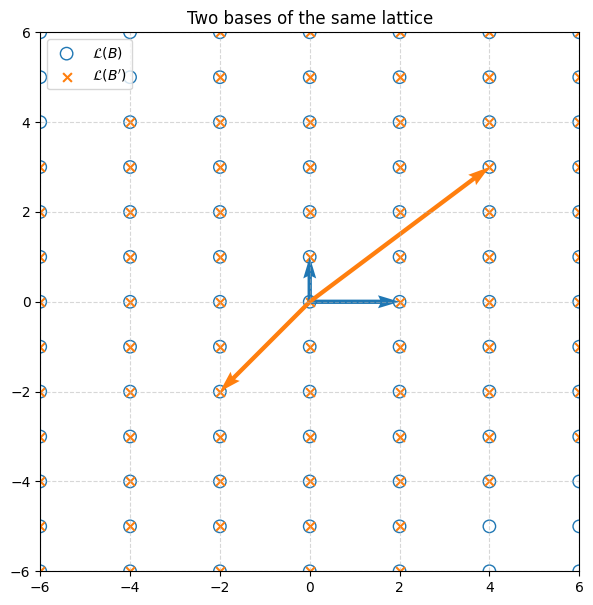

In [5]:
plt.figure(figsize=(7, 7))

# 1. The points of both lattices: circles for B, and cross for B'
plt.scatter(pts_B[:, 0], pts_B[:, 1], marker="o", s=80,
                facecolors="none", edgecolors="tab:blue", label=r"$\mathcal{L}(B)$")
plt.scatter(pts_Bp[:, 0], pts_Bp[:, 1], marker="x", s=40,
                color="tab:orange", label=r"$\mathcal{L}(B')$")

# 2. Basis vectors, in arrow form from the origin
for i in range(B.shape[1]):              # an arrow per B columns
    plt.quiver(0, 0, B[0, i], B[1, i], angles="xy", scale_units="xy",
                   scale=1, color="tab:blue", width=0.008)
for i in range(B_prime.shape[1]):
    plt.quiver(0, 0, B_prime[0, i], B_prime[1, i], angles="xy",
                   scale_units="xy", scale=1, color="tab:orange", width=0.008)

plt.xlim(-window, window)
plt.ylim(-window, window)
plt.gca().set_aspect("equal")            # same scale for both axis
plt.grid(True, linestyle="--", alpha=0.5)
plt.legend(loc="upper left")
plt.title("Two bases of the same lattice")
plt.show()


We proved above that $B$ and $B'$ generate the same lattice. However, when $N$ is small, some circles do not have a cross.

This is because the code only computes the points $x_1 b_1 + x_2 b_2$ with $|x_1|, |x_2| \le N$. With $B'$, some points close to the origin require large coefficients. For example:
$$(2,0) = 1\cdot(2,0) + 0\cdot(0,1) \quad \text{but} \quad (2,0) = 3\cdot(-2,-2) + 2\cdot(4,3).$$

In other words, $B$ is a **good basis**: its vectors are short and orthogonal, so the coefficients stay small. Whereas $B'$ is a **bad basis**: its vectors are long and almost parallel, so large coefficients are needed to reach some points, even close to the origin.

### Why LWE is a lattice problem

Let $A \in \mathbb{Z}_q^{m \times n}$. We define the lattice
$$\Lambda_q(A) = \{ Az \bmod q \mid z \in \mathbb{Z}^n \}.$$
Taking $z = s$, we see that $As \bmod q$ is a point of $\Lambda_q(A)$.

Recall that $b = As + e \bmod q$, where $e$ is small. The distance between $b$ and the lattice point $As$ is therefore $\|e\|$, which is small. As long as $e$ is small enough, $As$ is the lattice point closest to $b$, so recovering $s$ amounts to solving the **Closest Vector Problem (CVP)**.

This problem is hard for two reasons. First, the dimension $m$ is large, typically several hundred. Second, since $A$ is random, the only basis we can derive from it is a bad basis, like $B'$ in Figure 1.

The LLL algorithm turns a bad basis into a good one. This is why we study it in the next section.

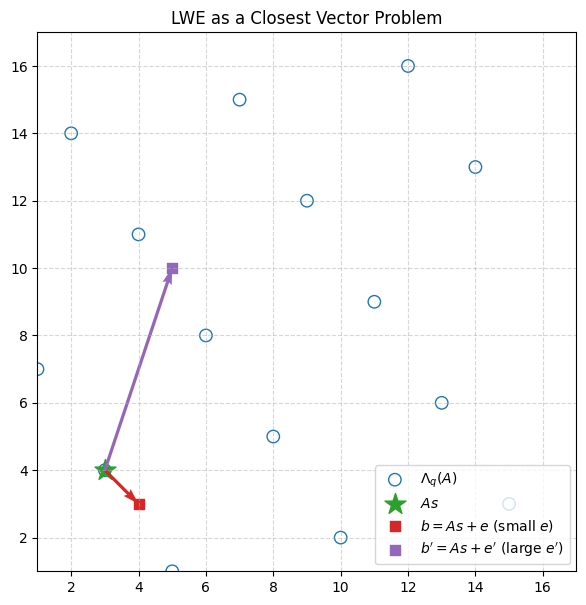

In [6]:
# Parameters of the toy example
q = 17
B_A = np.array([[1,7], [0, 17]]).T   # columns: (1,7) and (0,17)

As = np.array([3, 4])        # s = 3
e = np.array([1, -1])     # small error
e_big = np.array([2, 6]) # large error
b = As + e
b_big = As + e_big

pts = lattice_points(B_A, N)

plt.figure(figsize=(7, 7))

# 1. Lattice points
plt.scatter(pts[:, 0], pts[:, 1], marker="o", s=80,
            facecolors="none", edgecolors="tab:blue", label=r"$\Lambda_q(A)$")

# 2. The points As, b and b'
plt.scatter(As[0], As[1], marker="*", s=250, color="tab:green", label=r"$As$")
plt.scatter(b[0], b[1] , marker="s", s=60, color="tab:red", label=r"$b = As + e$ (small $e$)")
plt.scatter(b_big[0], b_big[1], marker="s", s=60, color="tab:purple", label=r"$b' = As + e'$ (large $e'$)")

# 3. The errors, as arrows starting from As
plt.quiver(As[0], As[1], e[0], e[1], angles="xy", scale_units="xy", scale=1,
           color="tab:red", width=0.006)
plt.quiver(As[0], As[1], e_big[0], e_big[1], angles="xy", scale_units="xy", scale=1,
           color="tab:purple", width=0.006)

plt.xlim(1, 17)
plt.ylim(1, 17)
plt.gca().set_aspect("equal")
plt.grid(True, linestyle="--", alpha=0.5)
plt.legend(loc="lower right")
plt.title("LWE as a Closest Vector Problem")
plt.show()

The figure shows the lattice $\Lambda_q(A)$ for $q = 17$ and $A = (1,7)^T$. With the secret $s = 3$, we have $As = (3,4)$, shown as the green star.

With a small error $e = (1,-1)$, the vector $b = (4,3)$ is not a lattice point, but the closest lattice point to $b$ is $As$. An attacker who solves CVP would therefore recover the right secret.

With a large error $e' = (2,6)$, the vector $b' = (5,10)$ is closer to $(4,11) = 4 \cdot (1,7) \bmod 17$ than to $As$. Solving CVP then gives $s = 4$, which is the wrong secret.

This illustrates the trade-off explained in the introduction: the larger $e$ is, the better $As$ is hidden, but an error that is too large makes decryption unreliable.

## 2. The LLL algorithm

The LLL algorithm takes as input a basis of a lattice and returns another basis of the same lattice. This new basis is *reduced*: its vectors are shorter and almost orthogonal. This is exactly what the attacker needs (see Section 1).

### 2.1 Why not simply use Gram-Schmidt?

Gram-Schmidt returns an orthogonal basis, so one might be tempted to use it directly. Recall that it computes
$$b_i^* = b_i - \sum_{j<i} \mu_{i,j}\, b_j^*, \qquad \mu_{i,j} = \frac{\langle b_i, b_j^* \rangle}{\|b_j^*\|^2}.$$

For example, $b_1 = (2,0)$ and $b_2 = (1,1)$ give $\mu_{2,1} = \tfrac12$ and $b_2^* = (0,1)$, which is not a lattice point: writing $(0,1) = x_1 b_1 + x_2 b_2$ would require $x_1 = -\tfrac12$.

To sum up, since the $\mu_{i,j}$ are not integers in general, the Gram-Schmidt vectors do not belong to the lattice.

### 2.2 Size reduction

The main idea is to replace $\mu_{i,j}$ by the nearest integer, denoted $\lfloor \mu_{i,j} \rceil$:
$$b_i \leftarrow b_i - \lfloor \mu_{i,j} \rceil\, b_j.$$
Since $\lfloor \mu_{i,j} \rceil$ is an integer, the new vector $b_i$ stays in the lattice.

For example, take $b_1 = (3,0)$ and $b_2 = (7,1)$. Then
$$\mu_{2,1} = \frac{\langle b_2, b_1 \rangle}{\|b_1\|^2} = \frac{21}{9} \approx 2.33, \qquad \lfloor \mu_{2,1} \rceil = 2,$$
so the new vector is
$$b_2 \leftarrow (7,1) - 2\cdot(3,0) = (1,1).$$
Its length drops from $\sqrt{50} \approx 7.07$ to $\sqrt{2} \approx 1.41$, and it is still a lattice point.

After this step, the new coefficient is $\mu_{2,1} = \tfrac{3}{9} = \tfrac13$. In general, size reduction always ensures
$$|\mu_{i,j}| \le \tfrac12 \quad \text{for all } j < i,$$
since we subtracted the nearest integer.

### 2.3 Is size reduction enough?

Consider the basis $b_1 = (7,1)$, $b_2 = (1,1)$. Their lengths are
$$\|b_1\| = \sqrt{7^2 + 1^2} = \sqrt{50} \approx 7.07, \qquad \|b_2\| = \sqrt{1^2 + 1^2} = \sqrt{2} \approx 1.41.$$
The problem is that the long vector comes first, whereas LLL should return a short first vector.

Let us first try size reduction:
$$\mu_{2,1} = \frac{\langle b_2, b_1 \rangle}{\|b_1\|^2} = \frac{7 \cdot 1 + 1 \cdot 1}{7^2 + 1^2} = \frac{8}{50} = 0.16, \qquad \lfloor \mu_{2,1} \rceil = 0,$$
so $b_2 \leftarrow b_2 - 0 \cdot b_1 = b_2$. Size reduction leaves the basis unchanged, so it is not enough on its own.

Instead, we swap $b_1$ and $b_2$:
$$\big((7,1),\ (1,1)\big) \longrightarrow \big((1,1),\ (7,1)\big).$$
The lattice does not change: the vectors are the same, only their order changes.

We now apply size reduction again, with $b_1 = (1,1)$ and $b_2 = (7,1)$:
$$\mu_{2,1} = \frac{7 \cdot 1 + 1 \cdot 1}{1^2 + 1^2} = \frac{8}{2} = 4, \qquad b_2 \leftarrow (7,1) - 4 \cdot (1,1) = (3,-3),$$
and $\|b_2\| = \sqrt{3^2 + (-3)^2} = \sqrt{18} \approx 4.24$.

We can check two things:
1. $\langle (1,1), (3,-3) \rangle = 3 - 3 = 0$, so the new basis is orthogonal.
2. $\left|\det\begin{pmatrix} 7 & 1 \\ 1 & 1 \end{pmatrix}\right| = \left|\det\begin{pmatrix} 1 & 3 \\ 1 & -3 \end{pmatrix}\right| = 6$, so both bases generate the same lattice, as expected.

**Lesson.** Size reduction alone is not enough: sometimes two consecutive vectors must be swapped, and a swap can unlock further size reduction. LLL therefore combines both operations. The remaining question is *when* to swap.

###2.4 The Lovász condition

A naive rule would be to swap $b_{k-1}$ and $b_k$ whenever $b_k$ is shorter than $b_{k-1}$. LLL refines this rule in two ways.

**First, it compares the "new parts" of the vectors.** In dimension greater than 2, what matters is not the total length of $b_k$, but what $b_k$ adds compared to the vectors placed before it. This is exactly the Gram-Schmidt vector $b_k^*$: the part of $b_k$ orthogonal to $b_1, \dots, b_{k-1}$.

We look at position $k-1$ and compare two scenarios:

- **Without a swap**, $b_{k-1}$ is at position $k-1$. Its new part is $b_{k-1}^*$, whose squared length is $\|b_{k-1}^*\|^2$.
- **With a swap**, $b_k$ would be at position $k-1$. Its new part would be $b_k^* + \mu_{k,k-1}\, b_{k-1}^*$. Since these two vectors are orthogonal, Pythagoras' theorem gives the squared length
$$\|b_k^*\|^2 + \mu_{k,k-1}^2\, \|b_{k-1}^*\|^2.$$

**Second, it only swaps if the gain is significant.** We keep the basis if
$$\underbrace{\|b_k^*\|^2 + \mu_{k,k-1}^2\, \|b_{k-1}^*\|^2}_{\text{with swap}} \;\ge\; \delta \underbrace{\|b_{k-1}^*\|^2}_{\text{without swap}},$$
which gives the official expression of the **Lovász condition**:
$$\|b_k^*\|^2 \ge \big(\delta - \mu_{k,k-1}^2\big)\, \|b_{k-1}^*\|^2.$$
If it fails, we swap $b_{k-1}$ and $b_k$.

**Why $\delta = \frac34$ and not $\delta = 1$?**

With $\delta = 1$, we would swap even for a tiny gain, and the algorithm could perform a huge number of swaps that barely improve the basis.

With $\delta = \frac34$, a swap only happens if the squared length at position $k-1$ decreases by at least 25%. Each swap therefore makes real progress, which guarantees that LLL terminates in polynomial time.

**In dimension 2.** For $k = 2$, we have $b_1^* = b_1$, and the left-hand side "with swap" is simply $\|b_2\|^2$. The Lovász condition becomes
$$\|b_2\|^2 \ge \tfrac34\, \|b_1\|^2.$$
In our example, the initial basis $b_1 = (7,1)$, $b_2 = (1,1)$ gives $2 < \frac34 \times 50 = 37.5$: the condition fails, so we swap. The final basis $b_1 = (1,1)$, $b_2 = (3,-3)$ gives $18 \ge \frac34 \times 2 = 1.5$: the condition holds, so we stop.

### 2.5 Implementation

We now implement LLL in Python, starting with Gram-Schmidt, which LLL needs at every step.

Note that, unlike in Section 1, the basis vectors are now the **rows** of `B`: `B[i]` is the vector $b_{i+1}$, since Python indices start at 0.

The function `gram_schmidt` returns the vectors $b_i^*$ and the coefficients $\mu_{i,j}$, computed with the formulas of Section 2.1. No rounding is applied here: rounding only happens in size reduction.

In [7]:
def gram_schmidt(B):
  n = B.shape[0]
  B_star = np.zeros(B.shape)        # floats: the b_i^* are not integer vectors
  mu = np.zeros((n, n))

  for i in range(n):
      B_star[i] = B[i]
      for j in range(i):            # j < i
          mu[i, j] = B[i] @ B_star[j] / np.dot(B_star[j], B_star[j])
          #print("before :", i, j, B_star[i])
          B_star[i] = B_star[i] - mu[i, j] * B_star[j]
          #print("after :", i, j, B_star[i])
  return B_star, mu

In [8]:
B = np.array([[7, 1], [1, 1]])
B_star, mu = gram_schmidt(B)
print(B_star)
print(mu)

[[ 7.    1.  ]
 [-0.12  0.84]]
[[0.   0.  ]
 [0.16 0.  ]]


The function `LLL` follows the algorithm described in the original paper by Lenstra, Lenstra and Lovász [1]. For simplicity, our version recomputes the Gram-Schmidt data after each modification, which is slower but easier to read. Since Python indices start at 0, $k$ starts at `1` instead of $2$, and stepping back after a swap is written `max(k - 1, 1)`.

In [9]:
def LLL(B, delta=0.75):
  B = B.copy()
  n = B.shape[0]
  k = 1

  while k < n:
    #Size reduction
    for j in range(k-1, -1, -1):
      B_star, mu = gram_schmidt(B)
      c = round(mu[k, j])
      B[k] = B[k] - c*B[j]

    #Lovasz condition
    B_star, mu = gram_schmidt(B)

    if np.dot(B_star[k], B_star[k]) >= (delta-mu[k, k-1]**2) * np.dot(B_star[k-1], B_star[k-1]):
      k = k+1

    else:
      B[[k-1, k]] = B[[k, k-1]]
      k = max(k-1, 1)
  return B

In [10]:
B = np.array([[7, 1], [1, 1]])
R = LLL(B)

print(f"|det(B)| = {round(abs(np.linalg.det(B)))}")
print(f"We apply LLL to B:\n{R}")
print(f"|det(LLL(B))| = {round(abs(np.linalg.det(R)))}")
print("Both determinants are equal, which is consistent with the fact that both bases generate the same lattice.")

|det(B)| = 6
We apply LLL to B:
[[ 1  1]
 [ 3 -3]]
|det(LLL(B))| = 6
Both determinants are equal, which is consistent with the fact that both bases generate the same lattice.


To test our implementation, the function `is_lll_reduced` checks that a basis satisfies both conditions of LLL: size reduction ($|\mu_{i,j}| \le \frac12$ for all $j < i$) and the Lovász condition at every position $k$.

In [11]:
def is_lll_reduced(B, delta=0.75):
  n = B.shape[0]
  B_star, mu = gram_schmidt(B)

  #1st condition : size reduction
  #for all i, and all i<j then |mu_i,j| <= 1/2

  for i in range(0, n):
    for j in range(0, i):
      if abs(mu[i, j]) > 1/2:
        return False

  #2nd condition : Lovasz
  #for all k, from 1 to n-1 : ||b^*_k||^2 >= (delta - mu_{k,k-1}^2)||b^*_k-1||^2

  for k in range(1, n):
    if np.dot(B_star[k], B_star[k]) < (delta - mu[k, k-1]**2)*np.dot(B_star[k-1], B_star[k-1]):
      return False

  return True



In [12]:
B = np.array([[7, 1], [1, 1]])
print(is_lll_reduced(B))         # False
print(is_lll_reduced(LLL(B)))    # True

False
True


The examples above are in dimension 2, where $k$ always equals 1. Many bugs only appear in higher dimension, so we also test `LLL` on random bases in dimension 5, checking both that the result is reduced and that the determinant is preserved.

In [13]:
for trial in range(20):
    B = np.random.randint(-20, 21, size=(5, 5))
    if round(np.linalg.det(B)) == 0:
        continue                     # not a basis: skip it
    R = LLL(B)
    assert is_lll_reduced(R), "LLL did not return a reduced basis!"
    assert round(abs(np.linalg.det(R))) == round(abs(np.linalg.det(B))), "Determinant changed!"
print("All tests passed")

All tests passed


We now have a working implementation of LLL. In the next section, we use it to attack LWE.

## 3. The attack

In this section, we use LLL to recover the secret $s$ from the public key $(A, b)$.

The problem is the following: breaking LWE amounts to solving CVP (see Section 1), but LLL finds short vectors, that is, it (approximately) solves SVP. We therefore need to transform CVP into SVP.

### 3.1 From CVP to SVP: Kannan's embedding

**Main idea.** We rewrite the LWE equation as $b - As = e$, where $e$ is short. If we add $b$ to the basis vectors, the lattice contains $b - As = e$. Finding the closest lattice point to $b$ thus becomes finding the short vector $e$, which is exactly what LLL does. This construction is called **Kannan's embedding** [2].

**Example.** Consider again the example of Figure 2: $q = 17$, $A = (1, 7)^T$, $s = 3$, $e = (1, -1)$ and $b = (4, 3)$. We build the matrix $M$ whose rows are the basis vectors:
$$M = \begin{pmatrix} 1 & 7 & 0 \\ 0 & 17 & 0 \\ 4 & 3 & 1 \end{pmatrix}.$$
The first two rows form a basis of $\Lambda_q(A)$, with an extra $0$. The last row is $b$, with an extra $1$.

We can then compute the following integer combination of the rows:
$$(4, 3, 1) - 3 \cdot (1, 7, 0) + 1 \cdot (0, 17, 0) = (1, -1, 1) = (e, 1).$$
The coefficient $3$ comes from $s = 3$: we subtract $As = (3, 21)$. The row $(0, 17, 0)$ accounts for the reduction modulo 17, since $-18 + 17 = -1$. Therefore, the short vector $(e, 1)$ belongs to the lattice generated by $M$.

**Why an extra coordinate?** First, without it, we would have three vectors in $\mathbb{R}^2$, which are necessarily linearly dependent, so they would not form a basis. With it, $\det M = 17 \neq 0$.

Second, the last coordinate of a lattice vector is the coefficient of $b$ in the combination. A vector ending with $\pm 1$ uses $b$ exactly once: this is the one we are looking for. A vector ending with $0$ does not use $b$ at all, so it gives no information about $s$.

In [14]:
M = np.array([[1, 7, 0],
              [0, 17, 0],
              [4, 3, 1]])
print(LLL(M))

[[ 1 -1  1]
 [ 0  1  2]
 [ 4  2 -1]]


LLL returns $(1, -1, 1) = (e, 1)$ as the first row: it finds the short vector, and therefore the error $e$, without knowing $s$.

### 3.2 Recovering $s$

LLL returned a reduced basis of the lattice generated by $M$:
$$\text{LLL}(M) = \begin{pmatrix} 1 & -1 & 1 \\ 0 & 1 & 2 \\ 4 & 2 & -1 \end{pmatrix}.$$
We look at the first row, because LLL guarantees that the first vector is short: $\|b_1\| \le 2^{(n-1)/2}\lambda_1$, where $\lambda_1$ is the length of a shortest nonzero lattice vector. Since $e$ is small, we expect $(e, 1)$ to be the shortest vector of this lattice. We denote by $v = (1, -1, 1)$ this first row.

How can we recover $s$ from $v$?

**Step 1: the sign.** If $v$ is in the lattice, then so is $-v$, and it has the same length. LLL may therefore return either $(e, 1)$ or $(-e, -1)$. To fix this, we look at the last coordinate of $v$, which is the coefficient of $b$ (see Section 3.1): if it equals $-1$, we multiply $v$ by $-1$. Then $e$ is given by the first $m$ coordinates of $v$:
$$v = (1, -1, 1) \;\Rightarrow\; e = (1, -1).$$
If the last coordinate is neither $1$ nor $-1$, then $v$ is not of the form $(e, \pm 1)$, and the attack has failed.

**Step 2: removing the noise.** We start from the LWE equation:
$$b = As + e \pmod q \quad\Longleftrightarrow\quad As = b - e \pmod q.$$
Everything on the right-hand side is known: $b$ is public, and $e$ has just been found. Hence
$$As = (4, 3) - (1, -1) = (3, 4) \pmod{17}.$$
This is the key point of the attack: once $e$ is known, the noise is removed, and LWE becomes a simple linear system.

**Step 3: solving the linear system.** We are looking for $s$ such that $As \equiv (3, 4) \pmod{17}$. Here, $A = (1, 7)^T$ and $s$ is an integer:
$$s \cdot \begin{pmatrix} 1 \\ 7 \end{pmatrix} \equiv \begin{pmatrix} 3 \\ 4 \end{pmatrix} \pmod{17} \quad\Longleftrightarrow\quad \begin{cases} s \equiv 3 \\ 7s \equiv 4 \end{cases} \pmod{17}.$$
The first equation gives $s = 3$, and the second one confirms it, since $7 \times 3 = 21 \equiv 4 \pmod{17}$. In general, when $n > 1$, this step amounts to solving a linear system of $n$ unknowns modulo $q$.

**Step 4: checking the result.** In a real attack, the attacker does not know the true secret. To check the result, they compute the error given by the recovered $s$ and verify that it is small:
$$b - As = (4, 3) - 3 \cdot (1, 7) = (1, -18) \equiv (1, -1) \pmod{17}.$$
Here we take the centred representative modulo $q$, between $-q/2$ and $q/2$. Since this error is small, $s = 3$ is very likely the right secret.

**When does the attack fail?** If $e$ is too large, $(e, 1)$ is no longer the shortest vector of the lattice. LLL then returns another short vector, which either does not end with $\pm 1$ or leads to a wrong $s$. This is the phenomenon illustrated in Figure 2, and we measure this threshold.

[1] A. K. Lenstra, H. W. Lenstra Jr. and L. Lovász, *Factoring polynomials with rational coefficients*, Mathematische Annalen 261 (1982), 515–534.

[2] R. Kannan, *Minkowski's convex body theorem and integer programming*, Mathematics of Operations Research 12(3) (1987), 415–440.